<a href="https://colab.research.google.com/github/simone-cappelletti/ai-sample-projects-library/blob/main/GreenTech_Solutions_Ltd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Riconoscimento di fiori per un’azienda AgriTech

**GreenTech Solutions Ltd.**, un'azienda all'avanguardia nel settore dell'agricoltura tecnologica, si trova ad affrontare la necessità critica di implementare un sistema avanzato di riconoscimento automatico dei fiori all'interno delle sue operazioni quotidiane.

La necessità di identificare automaticamente i fiori è cruciale per diversi motivi strategici e operativi:
- **Ottimizzazione delle Procedure Agricole**: Il riconoscimento automatico dei fiori consente di automatizzare e accelerare processi chiave all'interno dell'agricoltura, come la valutazione della salute delle piante, la gestione dei raccolti e la programmazione delle attività di manutenzione.
- **Monitoraggio della Salute Vegetale**: La capacità di identificare rapidamente e con precisione i fiori permette a GreenTech Solutions di monitorare la salute delle colture in tempo reale, individuando precocemente eventuali segnali di stress vegetativo, malattie o carenze nutrienti.
-**Decisioni Basate sui Dati**: Il riconoscimento automatico dei fiori fornisce dati dettagliati e affidabili che supportano decisioni agronomiche informate, come l'ottimizzazione dei trattamenti fitosanitari, la gestione dell'irrigazione e l'allocazione delle risorse agricole.
- **Efficienza Operativa e Riduzione dei Costi**: Automatizzare il processo di identificazione dei fiori riduce la dipendenza da risorse umane per attività ripetitive e migliorabili, consentendo a GreenTech Solutions di allocare le risorse in modo più efficiente e di ridurre i costi operativi complessivi.

**Benefici del Progetto**: L'implementazione di un modello avanzato di Computer Vision per il riconoscimento automatico dei fiori porterà numerosi vantaggi tangibili:
- **Aumento della Produttività**: Riduzione dei tempi dedicati all'identificazione manuale dei fiori, liberando risorse per attività più strategiche e ad alto valore aggiunto.
- **Miglioramento della Qualità**: Garanzia di una classificazione più precisa e uniforme dei fiori, migliorando la qualità complessiva dei servizi e dei prodotti agricoli offerti.
- **Innovazione Tecnologica**: Dimostrazione di leadership nell'adozione di tecnologie all'avanguardia, posizionando GreenTech Solutions come pioniere nell'agricoltura digitale e sostenibile.

**Dettagli del Progetto**: GreenTech Solutions Ltd. ha avviato un'iniziativa strategica per sviluppare un prototipo di modello di Computer Vision basato su intelligenza artificiale per il riconoscimento automatico dei fiori. Il [dataset](https://proai-datasets.s3.eu-west-3.amazonaws.com/progetto-finale-flowes.tar.gz) fornito include due categorie principali di fiori:
- Daisy (Margherita): 529 immagini di train, 163 di validation, 77 di test.
- Dandelion (Tarassaco): 746 immagini di train, 201 di validation, 105 di test.

**Obiettivo del Progetto**: Il principale obiettivo è sviluppare un modello altamente accurato e robusto, capace di classificare automaticamente i fiori con il miglior F1-score (macro) possibile sul dataset di test. L'uso di tecniche avanzate come il transfer learning e le data augmentations con la libreria **timm** di PyTorch è fortemente consigliato per ottimizzare le prestazioni del modello.

L'integrazione di questa soluzione innovativa permetterà a GreenTech Solutions Ltd. di consolidare ulteriormente la sua posizione nel mercato agricolo, offrendo soluzioni avanzate che migliorano l'efficienza operativa, promuovono la sostenibilità e soddisfano le crescenti esigenze dei clienti nel settore agricolo moderno.

# Implementazione

Affronteremo l'implementazione dividendola nelle seguenti fasi:
1. **Inizializzazione dell'ambiente**: imports, seeds, costanti, device...
2. **Caricamento, verifica ed esplorazione del dataset**: caricamento del dataset e breve EDA quantitativa e visuale.
4. **Preparazione della pipeline dei dati**: data augmentation, `DataLoader`...
5. **Definizione, addestramento e validazione del modello**: definizione, addestramento e validazione del modello scelto.
6. **Ottimizzazione hyperparameters**: ottimizzazione di un gruppo ristretto di hyperparameters.
7. **Valutazione finale e analisi risultati**.

## Inizializzazione dell'ambiente

Partiamo con l'inizializzazione dell'ambiente e:
- Importiamo le librerie necessarie.
- Definiamo eventuali seeds di riproducibilità, costanti, funzioni helper...
- Device di esecuzione (GPU se possibile).

In [ ]:
# Imports
import os
import random
import tarfile
import shutil
import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd
import timm
import json

from pathlib import Path
from urllib.request import urlopen
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.datasets.folder import IMG_EXTENSIONS
from torchvision.transforms import InterpolationMode
from tqdm.auto import tqdm
from sklearn.metrics import (
  accuracy_score,
  f1_score,
  classification_report,
  confusion_matrix,
  ConfusionMatrixDisplay
)

In [ ]:
# Constants

# Directories
ROOT_DIR = "./content/"
DATA_DIR = os.path.join(ROOT_DIR, "data")
OUTPUTS_DIR = os.path.join(ROOT_DIR, "outputs")
MODELS_DIR = os.path.join(ROOT_DIR, "models")
METRICS_DIR = os.path.join(ROOT_DIR, "metrics")

# Dataset
DATASET_NAME = "progetto-finale-flowes"
DATASET_URL = "https://proai-datasets.s3.eu-west-3.amazonaws.com/progetto-finale-flowes.tar.gz"

DAISY = "daisy"
DANDELION = "dandelion"

CLASSES = [DAISY, DANDELION]
CLASSES_EXPECTED_COUNTS = {
  "train": {DAISY: 529, DANDELION: 746},
  "valid": {DAISY: 163, DANDELION: 201},
  "test": {DAISY: 77, DANDELION: 105}
}

# Model
IMAGE_SIZE = 224
IMAGE_MEAN = (0.485, 0.456, 0.406)
IMAGE_STD = (0.229, 0.224, 0.225)
EVAL_RESIZE_SIZE = 256

N_EPOCH = 20
BATCH_SIZE = 32
PATIENCE = 3
MIN_DELTA = 0.0

# Seeds
SEED = 10

In [ ]:
# Helper functions
def set_seed(seed = SEED):
  """
  Set seed for reproducibility.
  """

  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)

  torch.backends.cudnn.deterministic = True
  torch.backends.cudnn.benchmark = False

def get_device():
  """
  Get device (CPU or GPU).
  """

  if torch.cuda.is_available():

    device = torch.device("cuda")
    print(f"Using GPU: {torch.cuda.get_device_name(0)}")

  else:

    device = torch.device("cpu")
    print("Using CPU")

  return device

def ensure_folder_exists(path):
  """
  Check whether or not a folder exists and create it if it doesn't.
  """

  Path(path).mkdir(parents = True, exist_ok = True)

def load_rgb_image(path):
  """
  Load an image and convert it to three RGB channels.
  """

  with Image.open(path) as image:

    return image.convert("RGB")

def is_valid_dir(directory):
  """
  Check whether or not a directory is valid.
  """

  return directory.is_dir() and not directory.name.startswith(".")

def is_valid_image_file(path):
  """
  Check whether or not a file is a valid image file.
  """

  return (
    path.is_file()
    and not path.name.startswith(".")
    and path.suffix.lower() in IMG_EXTENSIONS
  )

In [ ]:
# Init
set_seed()

device = get_device()

ensure_folder_exists(ROOT_DIR)
ensure_folder_exists(DATA_DIR)
ensure_folder_exists(OUTPUTS_DIR)
ensure_folder_exists(MODELS_DIR)
ensure_folder_exists(METRICS_DIR)

Using CPU


## Caricamento, verifica ed esplorazione del dataset

Proseguiamo con caricamento, verifica e semplice esplorazione del dataset.

In [ ]:
def load_dataset():
  """
  Load dataset.
  """

  archive = Path(DATA_DIR) / f"{DATASET_NAME}.tar.gz"
  destination = Path(DATA_DIR) / "Dataset"

  if not destination.is_dir():

    with urlopen(DATASET_URL, timeout = 30) as response:
      with open(archive, "wb") as file:
        shutil.copyfileobj(response, file)

    destination.mkdir(parents = True, exist_ok = True)

    with tarfile.open(archive, mode = "r:gz") as tar:
      tar.extractall(path = destination)

    print(f"Dataset extracted in: {destination.resolve()}")

  return archive, destination

In [ ]:
# Loading dataset
archive_path, destination_path = load_dataset()

dataset_train_dir = destination_path / DATASET_NAME / "train"
dataset_validation_dir = destination_path / DATASET_NAME / "valid"
dataset_test_dir = destination_path / DATASET_NAME / "test"

datasets_paths = {
  "train": Path(dataset_train_dir),
  "valid": Path(dataset_validation_dir),
  "test": Path(dataset_test_dir)
}

datasets_paths

/tmp/ipykernel_583/742109357.py:18: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path = destination)


Dataset extracted in: /content/content/data/Dataset


{'train': PosixPath('content/data/Dataset/progetto-finale-flowes/train'),
 'valid': PosixPath('content/data/Dataset/progetto-finale-flowes/valid'),
 'test': PosixPath('content/data/Dataset/progetto-finale-flowes/test')}

Verifichiamo semplicemente il numero di osservazioni per classe:

In [ ]:
def get_dataset_stats():
  """
  Get dataset statistics.
  """

  global images_paths
  rows = []

  for dataset, dataset_dir in datasets_paths.items():

    class_dirs = {
      directory.name.lower(): directory
      for directory in dataset_dir.iterdir()
      if is_valid_dir(directory) # Exclude metadata directories
    }

    expected_classes = set(CLASSES_EXPECTED_COUNTS[dataset])

    if set(class_dirs) != expected_classes:
      raise RuntimeError(
        f"Unexpected classes in {dataset}: {sorted(class_dirs)}. "
        f"Expected: {sorted(expected_classes)}"
      )

    images_paths[dataset] = {}

    for class_name in sorted(expected_classes):
      images = sorted(
        path
        for path in class_dirs[class_name].rglob("*")
        if is_valid_image_file(path) # Exclude metadata files
      )

      images_paths[dataset][class_name] = images

      expected = CLASSES_EXPECTED_COUNTS[dataset][class_name]

      rows.append({
        "dataset": dataset,
        "class": class_name,
        "images": len(images),
        "expected": expected,
        "count_matches": len(images) == expected
      })

  return pd.DataFrame(rows)

images_paths = {}
dataset_summary = get_dataset_stats()
display(dataset_summary)

print(f"\nTotal images: {dataset_summary['images'].sum()}")

if not dataset_summary["count_matches"].all():
    print("\nWARNING: some counts differ from the project description.")

,dataset,class,images,expected,count_matches
0,train,daisy,529,529,True
1,train,dandelion,746,746,True
2,valid,daisy,163,163,True
3,valid,dandelion,201,201,True
4,test,daisy,77,77,True
5,test,dandelion,105,105,True



Total images: 1821


Breve ispezione visiva di alcune osservazioni:

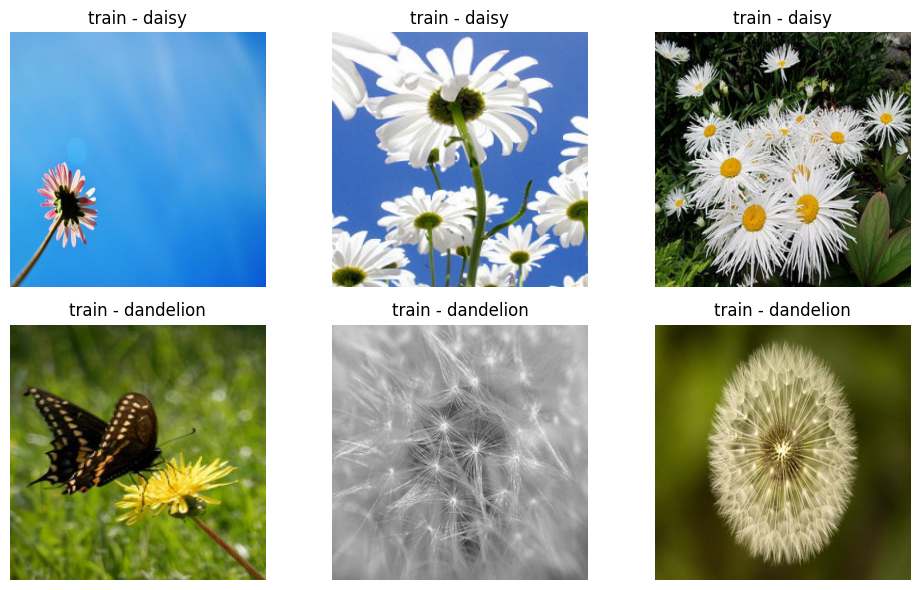

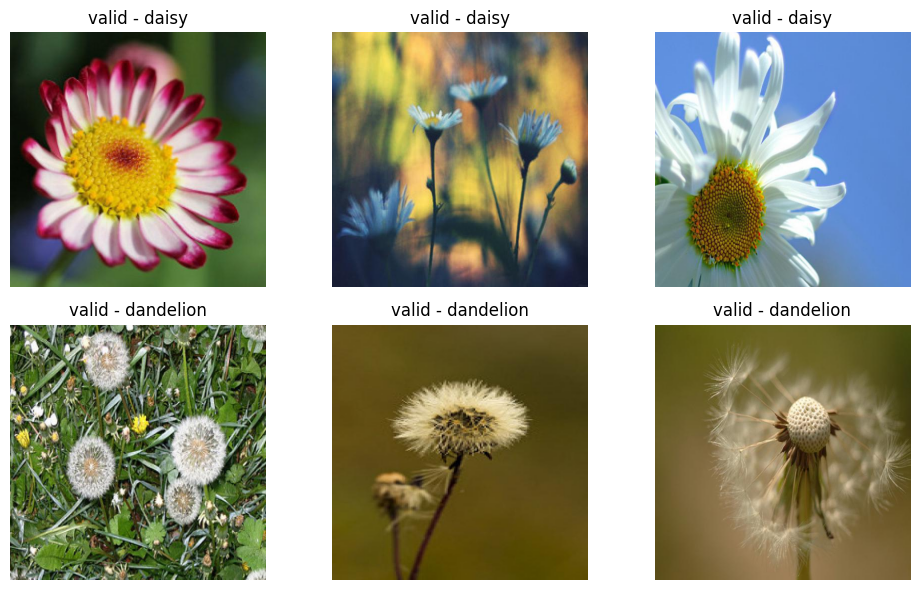

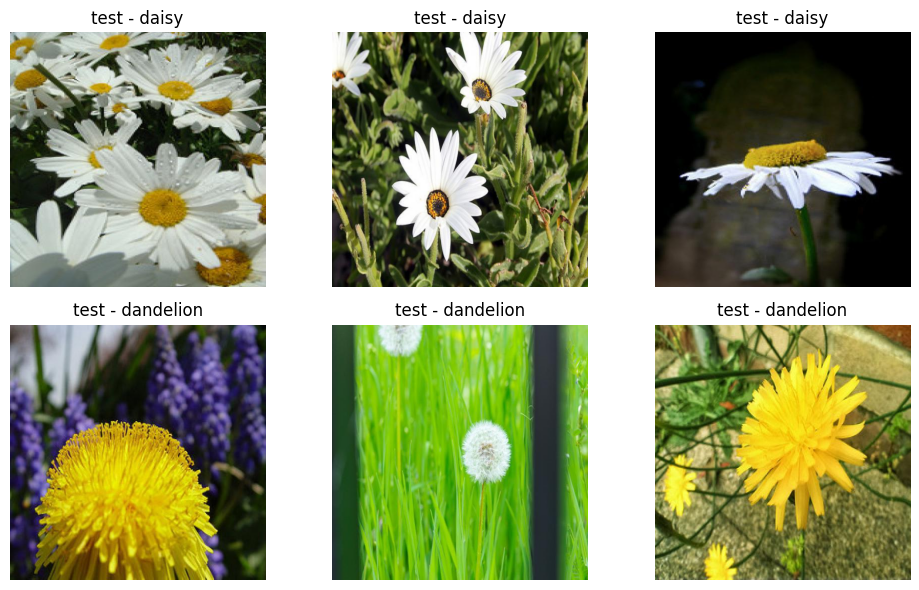

In [ ]:
def plot_random_train_images(dataset = "train"):
  """
  Plot 3 random images for each class from the specified dataset.
  """

  rng = random.Random()

  fig, axes = plt.subplots(
    nrows = len(CLASSES),
    ncols = 3,
    figsize = (10, 6),
    squeeze = False
  )

  train_dir = datasets_paths[dataset]

  for row, class_name in enumerate(CLASSES):

    class_dir = train_dir / class_name

    paths = sorted([
      path for path in class_dir.rglob("*")
      if is_valid_image_file(path)
    ])

    samples = rng.sample(paths, k = min(3, len(paths)))

    for column, ax in enumerate(axes[row]):

      ax.axis("off")

      if column >= len(samples):
        continue

      path = samples[column]

      ax.imshow(load_rgb_image(path))
      ax.set_title(f"{dataset} - {class_name}")

  plt.tight_layout()
  plt.show()

plot_random_train_images("train")
plot_random_train_images("valid")
plot_random_train_images("test")

## Preparazione della pipeline dei dati

Procediamo definendo le pipeline dei dati per ogni dataset. Ogni pipeline caricherà delle immagini, applicherà preprocessing e augmentation e produrrà i batch per il modello.

Al solito separiamo le trasformazioni del training da quelle di validation e test. Per quanto riguarda il training applichiamo:
1. `RandomResizedCrop`.
2. Un possibile flip orizzontale `RandomHorizontalFlip` (con probabilità del 50%).

Mentre a tutti i dataset applichiamo:
1. Solita trasformazione in tensore e normalizzazione.

In [ ]:
# Training
train_transform = transforms.Compose([
  transforms.RandomResizedCrop(
    size = IMAGE_SIZE,
    scale = (0.8, 1.0),
    ratio = (0.9, 1.1),
    interpolation = InterpolationMode.BICUBIC,
    antialias = True
  ),
  transforms.RandomHorizontalFlip(p = 0.5),
  transforms.ToTensor(),
  transforms.Normalize(mean = IMAGE_MEAN, std = IMAGE_STD)
])

# Validation and test
eval_transform = transforms.Compose([
  transforms.Resize(
    size = EVAL_RESIZE_SIZE,
    interpolation = InterpolationMode.BICUBIC,
    antialias = True
  ),
  transforms.CenterCrop(IMAGE_SIZE),
  transforms.ToTensor(),
  transforms.Normalize(mean = IMAGE_MEAN, std = IMAGE_STD)
])

datasets_transforms = {
  "train": train_transform,
  "valid": eval_transform,
  "test": eval_transform
}

Creazione dei data loaders:

In [ ]:
datasets_images = {
  split: datasets.ImageFolder(
    root = str(directory),
    transform = datasets_transforms[split],
    loader = load_rgb_image,
    is_valid_file = lambda path: is_valid_image_file(Path(path))
  )
  for split, directory in datasets_paths.items()
}

class_names = datasets_images["train"].classes
class_to_idx = datasets_images["train"].class_to_idx

# print(class_names)
# print(class_to_idx)

for split, dataset in datasets_images.items():

  if dataset.class_to_idx != class_to_idx:
    raise RuntimeError(
      f"Inconsistent class-to-index mapping in {split}: "
      f"{dataset.class_to_idx}"
    )

  inspected_paths = {
    path.resolve()
    for paths in images_paths[split].values()
    for path in paths
  }

  loaded_paths = {
    Path(path).resolve()
    for path, _ in dataset.samples
  }

  if loaded_paths != inspected_paths:
    raise RuntimeError(
      f"Loaded files differ from phase 2 inspection in {split}. "
      f"Loaded: {len(loaded_paths)}, Inspected: {len(inspected_paths)}"
    )

print(f"\nClasses: {class_names}")
print(f"Class mapping: {class_to_idx}")


Classes: ['daisy', 'dandelion']
Class mapping: {'daisy': 0, 'dandelion': 1}


In [ ]:
data_loaders = {
  split: DataLoader(
    dataset = datasets_images[split],
    batch_size = BATCH_SIZE,
    shuffle = (split == "train"),
    pin_memory = (device.type == "cuda"),
    drop_last = False
  )
  for split in datasets_paths.keys()
}

for split, loader in data_loaders.items():
  print(f"{split}: {len(loader.dataset)} images, {len(loader)} batches")

train: 1275 images, 40 batches
valid: 364 images, 12 batches
test: 182 images, 6 batches


Ed ora effettuiamo un controllo visivo dopo la data augmentation creando un data loader temporaneo ed annullando la normalizzazione.

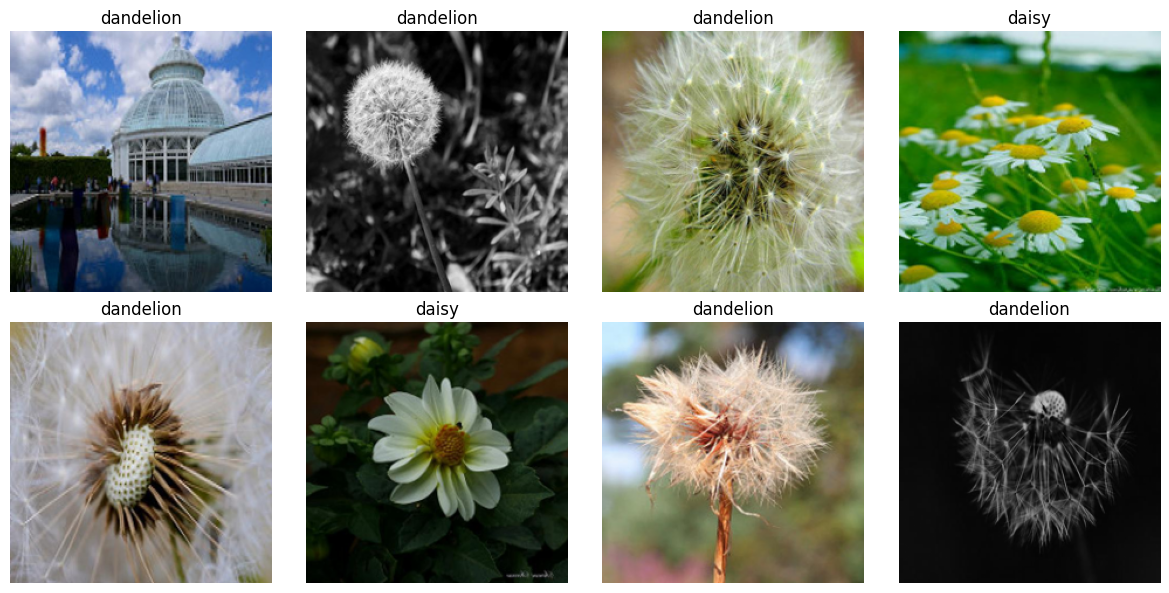

In [ ]:
# Data loader
temp_loader = DataLoader(
  dataset = datasets_images["train"],
  batch_size = min(8, BATCH_SIZE),
  shuffle = True
)

batch_images, batch_labels = next(iter(temp_loader))

# Mean
mean = torch.tensor(
  IMAGE_MEAN,
  dtype = batch_images.dtype
).view(1, 3, 1, 1)

# Std
std = torch.tensor(
  IMAGE_STD,
  dtype = batch_images.dtype
).view(1, 3, 1, 1)

preview_images = (batch_images * std + mean).clamp(0, 1)

fig, axes = plt.subplots(
  nrows = 2,
  ncols = 4,
  figsize = (12, 6)
)

for index, ax in enumerate(axes.flat):

  ax.axis("off")

  if index >= len(preview_images):
    continue

  ax.imshow(preview_images[index].permute(1, 2, 0).numpy())

  label = batch_labels[index].item()
  ax.set_title(class_names[label])

plt.tight_layout()
plt.show()

## Definizione, addestramento e validazione del modello

Passiamo alla definizione, addestramento e validazione del modello.

Partiremo da una rete baseline sulla quale andremo a fare un leggero fine-tuning. Utilizzeremo anche le classiche tecniche di industrializzazione del codice come early stopping e salvataggio di checkpoint.

Come configurazione iniziale adotteremo:

| Impostazione         | Scelta                                     |
| -------------------- | ------------------------------------------ |
| Modello              | mobilenetv3_small_100.lamb_in1k            |
| Pesi iniziali        | ImageNet-1k                                |
| Loss                 | CrossEntropyLoss                           |
| Ottimizzatore        | AdamW                                      |
| Learning rate        | 1e-4                                       |
| Weight decay         | 1e-4                                       |
| Epoche massime       | 20                                         |
| Early stopping       | 3 epoche senza miglioramento del F1 macro  |
| Miglioramento minimo | 0.0: qualsiasi miglioramento va bene       |
| Metriche             | Loss, accuracy e F1 macro                  |
| Batch size           | 32 |

In [ ]:
set_seed(SEED)

learning_rate = 1e-4
weight_decay = 1e-4

Configurazione iniziale della baseline e creazione modello baseline:

In [ ]:
baseline_model_name = "mobilenetv3_small_100.lamb_in1k"

baseline_config = {
  "model_name": baseline_model_name,
  "pretrained": True,
  "epochs": N_EPOCH,
  "learning_rate": learning_rate,
  "weight_decay": weight_decay,
  "patience": PATIENCE,
  "min_delta": MIN_DELTA
}

baseline_checkpoint_path = (Path(MODELS_DIR) / f"{baseline_model_name}.pth")
baseline_history_path = (Path(METRICS_DIR) / f"{baseline_model_name}.csv")

baseline_checkpoint_path.parent.mkdir(parents = True, exist_ok = True)
baseline_history_path.parent.mkdir(parents = True, exist_ok = True)

In [ ]:
model = timm.create_model(
  baseline_config["model_name"],
  pretrained = baseline_config["pretrained"],
  num_classes = len(CLASSES)
)

baseline_data_config = timm.data.resolve_model_data_config(model)

model = model.to(device)

total_parameters = sum(
  parameter.numel()
  for parameter in model.parameters()
)

trainable_parameters = sum(
  parameter.numel()
  for parameter in model.parameters()
  if parameter.requires_grad
)

print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")

model.safetensors: reconstructing file:   0%|          |  0.00B / 10.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Total parameters: 1,519,906
Trainable parameters: 1,519,906


Impostiamo funzione di loss e ottimizzatore:

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
  model.parameters(),
  lr = baseline_config["learning_rate"],
  weight_decay = baseline_config["weight_decay"]
)

Definiamo un'unica funzione per training e validation su singola epoca:

In [ ]:
def run_epoch(model, data_loader, criterion, device, optimizer = None):
  """
  Run a single epoch of training or validation.
  """

  is_training = optimizer is not None
  model.train(is_training)

  total_loss = 0.0
  total_samples = 0

  targets_all = []
  predictions_all = []

  progress_bar = tqdm(
    data_loader,
    desc = "Train" if is_training else "Valid",
    leave = False
  )

  with torch.set_grad_enabled(is_training):

    for images, targets in progress_bar:

      images = images.to(device, non_blocking = True)
      targets = targets.to(device, non_blocking = True)

      if is_training:
        optimizer.zero_grad(set_to_none = True)

      logits = model(images)
      loss = criterion(logits, targets)

      if is_training:
        loss.backward()
        optimizer.step()

      batch_size = targets.size(0)

      total_loss += loss.item() * batch_size
      total_samples += batch_size

      predictions = logits.argmax(dim = 1)

      targets_all.extend(targets.detach().cpu().tolist())
      predictions_all.extend(predictions.detach().cpu().tolist())

      progress_bar.set_postfix(loss = f"{total_loss / total_samples:.4f}")

  return {
    "loss": total_loss / total_samples,
    "accuracy": accuracy_score(targets_all, predictions_all),
    "f1_macro": f1_score(
      targets_all,
      predictions_all,
      labels = list(range(model.num_classes)),
      average = "macro",
      zero_division = 0
    )
  }

Ora ci dedicheremo all'addestramento di tutti i parametri della rete:

In [ ]:
baseline_history = []

best_valid_f1 = float("-inf")
epochs_without_improvement = 0

for epoch in range(1, baseline_config["epochs"] + 1):

  print(f"\nEpoch {epoch}/{baseline_config['epochs']}")

  train_metrics = run_epoch(
    model = model,
    data_loader = data_loaders["train"],
    criterion = criterion,
    device = device,
    optimizer = optimizer
  )

  valid_metrics = run_epoch(
    model = model,
    data_loader = data_loaders["valid"],
    criterion = criterion,
    device = device
  )

  epoch_metrics = {
    "epoch": epoch,
    "learning_rate": optimizer.param_groups[0]["lr"],
    "train_loss": train_metrics["loss"],
    "train_accuracy": train_metrics["accuracy"],
    "train_f1_macro": train_metrics["f1_macro"],
    "valid_loss": valid_metrics["loss"],
    "valid_accuracy": valid_metrics["accuracy"],
    "valid_f1_macro": valid_metrics["f1_macro"]
  }

  baseline_history.append(epoch_metrics)

  pd.DataFrame(baseline_history).to_csv(baseline_history_path, index=False)

  print(
    f"Train | loss: {train_metrics['loss']:.4f} "
    f"| accuracy: {train_metrics['accuracy']:.4f} "
    f"| F1 macro: {train_metrics['f1_macro']:.4f}"
  )

  print(
    f"Valid | loss: {valid_metrics['loss']:.4f} "
    f"| accuracy: {valid_metrics['accuracy']:.4f} "
    f"| F1 macro: {valid_metrics['f1_macro']:.4f}"
  )

  improved = (
    valid_metrics["f1_macro"]
    > best_valid_f1 + baseline_config["min_delta"]
  )

  if improved:

      best_valid_f1 = valid_metrics["f1_macro"]
      epochs_without_improvement = 0

      checkpoint = {
        "epoch": epoch,
        "model_name": baseline_config["model_name"],
        "num_classes": len(CLASSES),
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_valid_f1_macro": best_valid_f1,
        "train_metrics": train_metrics,
        "valid_metrics": valid_metrics,
        "class_to_idx": class_to_idx,
        "config": dict(baseline_config),
        "data_config": dict(baseline_data_config)
      }

      torch.save(checkpoint, baseline_checkpoint_path)

      print(f"Checkpoint updated: F1 macro validation = {best_valid_f1:.4f}")

  else:

      epochs_without_improvement += 1

      print(f"No improvement: {epochs_without_improvement}/{baseline_config['patience']}")

  if (epochs_without_improvement >= baseline_config["patience"]):

      print("Early stopping: training interrupted.")
      break

baseline_history_df = pd.DataFrame(baseline_history)

display(baseline_history_df)


Epoch 1/20


Train:   0%|          | 0/40 [00:00<?, ?it/s]

Valid:   0%|          | 0/12 [00:00<?, ?it/s]

Train | loss: 1.3261 | accuracy: 0.8306 | F1 macro: 0.8262
Valid | loss: 0.4438 | accuracy: 0.9313 | F1 macro: 0.9296
Checkpoint updated: F1 macro validation = 0.9296

Epoch 2/20


Train:   0%|          | 0/40 [00:00<?, ?it/s]

...

Train | loss: 0.0393 | accuracy: 0.9859 | F1 macro: 0.9855
Valid | loss: 0.2978 | accuracy: 0.9313 | F1 macro: 0.9303
No improvement: 2/3

Epoch 8/20


Train:   0%|          | 0/40 [00:00<?, ?it/s]

Valid:   0%|          | 0/12 [00:00<?, ?it/s]

Train | loss: 0.0811 | accuracy: 0.9796 | F1 macro: 0.9790
Valid | loss: 0.3291 | accuracy: 0.9203 | F1 macro: 0.9194
No improvement: 3/3
Early stopping: training interrupted.


,epoch,learning_rate,train_loss,train_accuracy,train_f1_macro,valid_loss,valid_accuracy,valid_f1_macro
0,1,0.0001,1.326077,0.830588,0.826182,0.443751,0.931319,0.929592
1,2,0.0001,0.272392,0.949020,0.947211,0.472935,0.901099,0.900799
2,3,0.0001,0.108107,0.970196,0.969307,0.361762,0.934066,0.933260
3,4,0.0001,0.059517,0.981176,0.980615,0.267241,0.931319,0.930678
4,5,0.0001,0.042001,0.983529,0.983024,0.254862,0.942308,0.941705
5,6,0.0001,0.039755,0.989020,0.988698,0.345098,0.925824,0.925209
6,7,0.0001,0.039275,0.985882,0.985461,0.297798,0.931319,0.930253
7,8,0.0001,0.081150,0.979608,0.979000,0.329141,0.920330,0.919404


## Ottimizzazione hyperparameters

Passiamo all'ottimizzazione degli hyperparameters. Aggiungeremo semplicemente due ulteriori esperimenti, uno per variare learning rate ed uno per aggiungere una trasformazione in più nella data augmentation.

Pertanto manteniamo intatta gran parte della configurazione e testiamo:
- Learning rate minore a `5e-5`.
- `ColorJitter` come trasformazione ulteriore.

In [ ]:
# Additional experiments
experiment_configs = [
  {
    "name": "lr_5e_5",
    "learning_rate": 5e-5,
    "augmentation": "baseline"
  },
  {
    "name": "color_jitter",
    "learning_rate": baseline_config["learning_rate"],
    "augmentation": "color_jitter"
  }
]

color_jitter_transform = transforms.Compose([
  transforms.RandomResizedCrop(
    size = IMAGE_SIZE,
    scale = (0.8, 1.0),
    ratio = (0.9, 1.1),
    interpolation = InterpolationMode.BICUBIC,
    antialias = True
  ),
  transforms.RandomHorizontalFlip(p = 0.5),
    transforms.ColorJitter(
      brightness = 0.15,
      contrast = 0.15,
      saturation = 0.10,
      hue = 0.0
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean = IMAGE_MEAN, std = IMAGE_STD)
])

experiment_transforms = {
  "baseline": train_transform,
  "color_jitter": color_jitter_transform
}

Definiamo una funzione che riutilizza `run_epoch` ma che crea un modello, un ottimizzatore e un `DataLoader` di training indipendenti per ogni esperimento aggiuntivo.

In [ ]:
def run_experiment(experiment):
  """
  Train a configuration and save its best validation checkpoint.
  """

  set_seed(SEED)

  name = experiment["name"]

  config = {
    **baseline_config,
    "name": name,
    "learning_rate": experiment["learning_rate"],
    "augmentation": experiment["augmentation"],
    "seed": SEED
  }

  checkpoint_path = Path(MODELS_DIR) / f"{name}.pth"
  history_path = Path(METRICS_DIR) / f"{name}.csv"

  train_dataset = datasets.ImageFolder(
    root = str(datasets_paths["train"]),
    transform = experiment_transforms[config["augmentation"]],
    loader = load_rgb_image,
    is_valid_file = lambda path: is_valid_image_file(Path(path))
  )

  generator = torch.Generator().manual_seed(SEED)

  train_loader = DataLoader(
    dataset = train_dataset,
    batch_size = BATCH_SIZE,
    shuffle = True,
    generator = generator,
    pin_memory = (device.type == "cuda"),
    drop_last = False
  )

  experiment_model = timm.create_model(
    config["model_name"],
    pretrained = config["pretrained"],
    num_classes = len(class_names)
  ).to(device)

  data_config = timm.data.resolve_model_data_config(experiment_model)

  experiment_criterion = nn.CrossEntropyLoss()

  experiment_optimizer = torch.optim.AdamW(
    experiment_model.parameters(),
    lr = config["learning_rate"],
    weight_decay = config["weight_decay"]
  )

  history = []
  best_f1 = float("-inf")
  epochs_without_improvement = 0

  for epoch in range(1, config["epochs"] + 1):

    print(f"\n{name} | Epoch {epoch}/{config['epochs']}")

    train_metrics = run_epoch(
      model = experiment_model,
      data_loader = train_loader,
      criterion = experiment_criterion,
      device = device,
      optimizer = experiment_optimizer
    )

    valid_metrics = run_epoch(
      model = experiment_model,
      data_loader = data_loaders["valid"],
      criterion = experiment_criterion,
      device = device
    )

    history.append({
      "epoch": epoch,
      "learning_rate": config["learning_rate"],
      **{
        f"train_{key}": value
        for key, value in train_metrics.items()
      },
      **{
        f"valid_{key}": value
        for key, value in valid_metrics.items()
      }
    })

    pd.DataFrame(history).to_csv(history_path, index = False)

    print(
      f"Train F1: {train_metrics['f1_macro']:.4f} | "
      f"Valid F1: {valid_metrics['f1_macro']:.4f} | "
      f"Valid loss: {valid_metrics['loss']:.4f}"
    )

    improved = (valid_metrics["f1_macro"] > best_f1 + config["min_delta"])

    if improved:

      best_f1 = valid_metrics["f1_macro"]
      epochs_without_improvement = 0

      torch.save(
        {
          "epoch": epoch,
          "model_name": config["model_name"],
          "num_classes": len(class_names),
          "model_state_dict": experiment_model.state_dict(),
          "optimizer_state_dict": experiment_optimizer.state_dict(),
          "best_valid_f1_macro": best_f1,
          "train_metrics": train_metrics,
          "valid_metrics": valid_metrics,
          "class_to_idx": dict(class_to_idx),
          "config": config,
          "data_config": dict(data_config)
        },
        checkpoint_path
      )

      print("Checkpoint updated.")

    else:

      epochs_without_improvement += 1

    if epochs_without_improvement >= config["patience"]:

      print("Early stopping.")
      break

  del experiment_model, experiment_optimizer

  if device.type == "cuda":
    torch.cuda.empty_cache() # Clear cuda cache

  return checkpoint_path

Eseguiamo i due nuovi esperimenti e confrontiamo i checkpoint migliori.

In [ ]:
experiment_checkpoint_paths = {"baseline": Path(baseline_checkpoint_path)}

for experiment in experiment_configs:
  experiment_checkpoint_paths[experiment["name"]] = (run_experiment(experiment))


lr_5e_5 | Epoch 1/20


Train:   0%|          | 0/40 [00:00<?, ?it/s]

Valid:   0%|          | 0/12 [00:00<?, ?it/s]

Train F1: 0.8218 | Valid F1: 0.9014 | Valid loss: 0.4998
Checkpoint updated.

lr_5e_5 | Epoch 2/20


Train:   0%|          | 0/40 [00:00<?, ?it/s]

...

Valid:   0%|          | 0/12 [00:00<?, ?it/s]

Train F1: 0.9701 | Valid F1: 0.9134 | Valid loss: 0.3048

color_jitter | Epoch 4/20


Train:   0%|          | 0/40 [00:00<?, ?it/s]

Valid:   0%|          | 0/12 [00:00<?, ?it/s]

Train F1: 0.9774 | Valid F1: 0.9216 | Valid loss: 0.2683
Early stopping.


Infine creiamo una tabella con le metriche di validation e selezioniamo l’F1 macro di validation più alto.

In [ ]:
experiment_rows = []

for name, checkpoint_path in experiment_checkpoint_paths.items():

  checkpoint = torch.load(
    checkpoint_path,
    map_location = "cpu",
    weights_only = True
  )

  experiment_rows.append({
    "experiment": name,
    "learning_rate": checkpoint["config"]["learning_rate"],
    "augmentation": checkpoint["config"].get("augmentation", "baseline"),
    "best_epoch": checkpoint["epoch"],
    "valid_loss": checkpoint["valid_metrics"]["loss"],
    "valid_accuracy": checkpoint["valid_metrics"]["accuracy"],
    "valid_f1_macro": checkpoint["valid_metrics"]["f1_macro"],
    "checkpoint_path": str(checkpoint_path)
  })

experiments_df = pd.DataFrame(experiment_rows)

# With the same F1 we prefer the baseline.
experiments_df["selection_priority"] = (
  experiments_df["experiment"]
  .map({
    "baseline": 0,
    "lr_5e_5": 1,
    "color_jitter": 2
  })
)

experiments_df = (
  experiments_df
  .sort_values(["valid_f1_macro", "selection_priority"], ascending = [False, True])
  .drop(columns = "selection_priority")
  .reset_index(drop = True)
)

baseline_f1 = experiments_df.loc[experiments_df["experiment"] == "baseline", "valid_f1_macro"].iloc[0]

experiments_df["delta_f1_vs_baseline"] = (experiments_df["valid_f1_macro"] - baseline_f1)
experiments_df.to_csv(Path(METRICS_DIR) / "experiments_summary.csv", index = False)

display(experiments_df)

,experiment,learning_rate,augmentation,best_epoch,valid_loss,valid_accuracy,valid_f1_macro,checkpoint_path,delta_f1_vs_baseline
0,baseline,0.00010,baseline,5,0.254862,0.942308,0.941705,content/models/mobilenetv3_small_100.lamb_in1k...,0.000000
1,lr_5e_5,0.00005,baseline,6,0.262690,0.936813,0.936154,content/models/lr_5e_5.pth,-0.005552
2,color_jitter,0.00010,color_jitter,1,0.487605,0.923077,0.921716,content/models/color_jitter.pth,-0.019990


Ricarichiamo il modello vincitore e salviamone una copia da utilizzare poi nell'ultima fase.

In [ ]:
selected_row = experiments_df.iloc[0]
selected_checkpoint_path = Path(selected_row["checkpoint_path"])

selected_checkpoint = torch.load(
  selected_checkpoint_path,
  map_location = "cpu",
  weights_only = True
)

model = timm.create_model(
  selected_checkpoint["model_name"],
  pretrained = False,
  num_classes = selected_checkpoint["num_classes"]
)

model.load_state_dict(selected_checkpoint["model_state_dict"])

model = model.to(device)
model.eval()

final_checkpoint_path = Path(MODELS_DIR) / "selected_model.pth"

selected_checkpoint["selected_experiment"] = (selected_row["experiment"])

torch.save(selected_checkpoint, final_checkpoint_path)

print(f"Selected experiment: {selected_row['experiment']}")
print(f"Best epoch: {selected_checkpoint['epoch']}")
print(f"Validation F1 macro: {selected_checkpoint['valid_metrics']['f1_macro']:.4f}")

Selected experiment: baseline
Best epoch: 5
Validation F1 macro: 0.9417


In [ ]:
validation_rows = []
sample_offset = 0

validation_loader = data_loaders["valid"]
validation_dataset = validation_loader.dataset

with torch.inference_mode():

  for images, targets in validation_loader:

    logits = model(images.to(device))
    probabilities = logits.softmax(dim = 1)

    confidences, predictions = probabilities.max(dim = 1)

    for target, prediction, confidence in zip(
      targets.tolist(),
      predictions.cpu().tolist(),
      confidences.cpu().tolist()
    ):
      image_path, expected_target = (validation_dataset.samples[sample_offset])

      if target != expected_target:
        raise RuntimeError("Validation sample order is inconsistent.")

      validation_rows.append({
        "path": image_path,
        "true_class": class_names[target],
        "predicted_class": class_names[prediction],
        "predicted_probability": confidence,
        "correct": target == prediction
      })

      sample_offset += 1

validation_predictions_df = pd.DataFrame(validation_rows)
validation_predictions_df.to_csv(Path(METRICS_DIR) / "validation_predictions.csv", index = False)

validation_errors_df = (
  validation_predictions_df
  .loc[lambda frame: ~frame["correct"]]
  .sort_values("predicted_probability", ascending = False)
)

print(f"Validation errors: {len(validation_errors_df)}/{len(validation_predictions_df)}")

display(validation_errors_df.head(10))

Validation errors: 21/364


,path,true_class,predicted_class,predicted_probability,correct
362,content/data/Dataset/progetto-finale-flowes/va...,dandelion,daisy,0.999986,False
169,content/data/Dataset/progetto-finale-flowes/va...,dandelion,daisy,0.999524,False
107,content/data/Dataset/progetto-finale-flowes/va...,daisy,dandelion,0.999399,False
272,content/data/Dataset/progetto-finale-flowes/va...,dandelion,daisy,0.999296,False
75,content/data/Dataset/progetto-finale-flowes/va...,daisy,dandelion,0.999216,False
10,content/data/Dataset/progetto-finale-flowes/va...,daisy,dandelion,0.998136,False
73,content/data/Dataset/progetto-finale-flowes/va...,daisy,dandelion,0.997218,False
345,content/data/Dataset/progetto-finale-flowes/va...,dandelion,daisy,0.995695,False
267,content/data/Dataset/progetto-finale-flowes/va...,dandelion,daisy,0.991677,False
2,content/data/Dataset/progetto-finale-flowes/va...,daisy,dandelion,0.977085,False


Visualizziamo gli errori con la probabilità assegnata più alta:

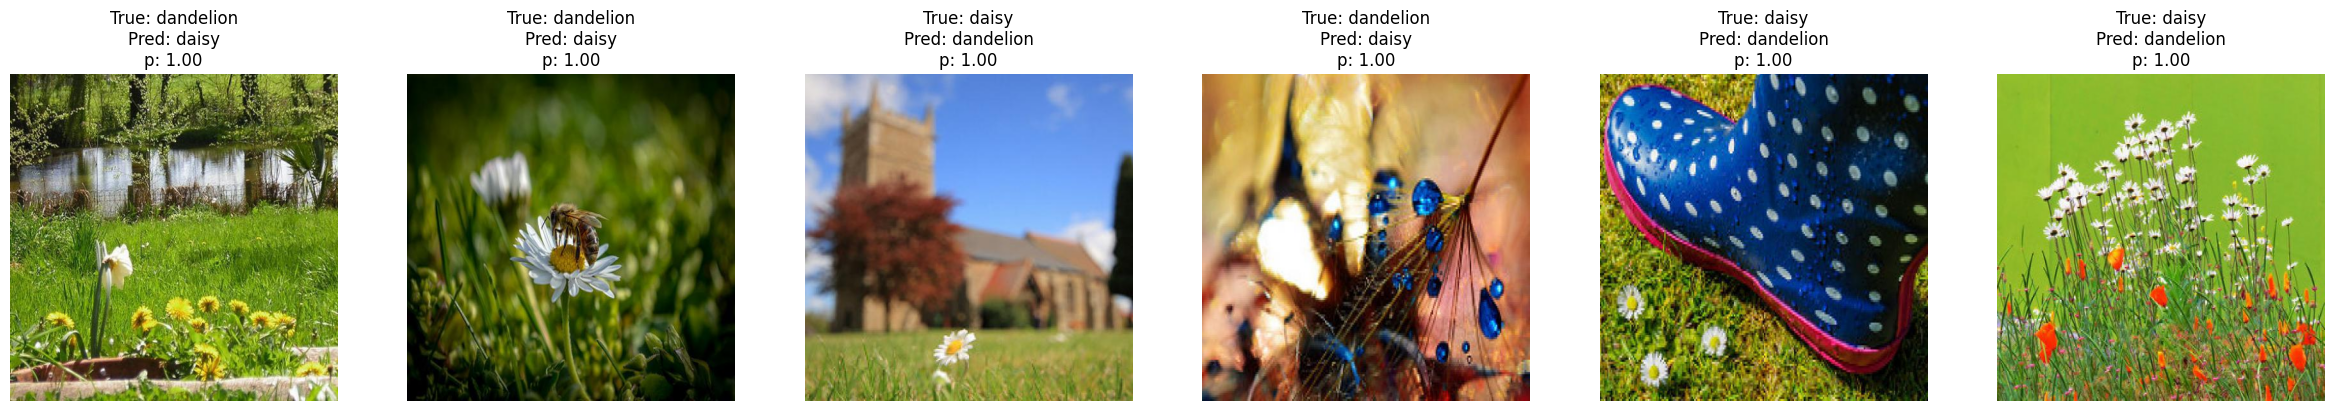

In [ ]:
errors_preview = validation_errors_df.head(6)

fig, axes = plt.subplots(
  nrows = 1,
  ncols = len(errors_preview),
  figsize = (4 * len(errors_preview), 4),
  squeeze = False
)

for ax, (_, row) in zip(axes.flat, errors_preview.iterrows()):

  ax.imshow(load_rgb_image(row["path"]))
  ax.set_title(
    f"True: {row['true_class']}\n"
    f"Pred: {row['predicted_class']}\n"
    f"p: {row['predicted_probability']:.2f}"
  )

  ax.axis("off")

plt.tight_layout()
plt.show()

Notiamo che la difficoltà è sicuramente quando lo sfondo è predominante ed il soggetto è piccolo in confronto allo sfondo stesso.

## Valutazione finale e analisi risultati

Passiamo alla valutazione finale sul dataset di test e all'analisi dei risultati.

Cominciamo ricaricando il miglior modello:

In [ ]:
final_checkpoint_path = Path(MODELS_DIR) / "selected_model.pth"

final_checkpoint = torch.load(
  final_checkpoint_path,
  map_location = "cpu",
  weights_only = True
)

inference_class_to_idx = final_checkpoint["class_to_idx"]

inference_class_names = [
  class_name
  for class_name, class_index in sorted(
    inference_class_to_idx.items(),
    key = lambda item: item[1]
  )
]

# print(inference_class_to_idx)
# print(inference_class_names)

model = timm.create_model(
  final_checkpoint["model_name"],
  pretrained = False,
  num_classes = final_checkpoint["num_classes"]
)

model.load_state_dict(final_checkpoint["model_state_dict"])

model = model.to(device)
model.eval()

print(
  "Selected experiment:",
  final_checkpoint.get("selected_experiment", "not specified")
)
print("Best epoch:", final_checkpoint["epoch"])
print(
  "Validation F1 macro:",
  f"{final_checkpoint['valid_metrics']['f1_macro']:.4f}"
)

Selected experiment: baseline
Best epoch: 5
Validation F1 macro: 0.9417


Valutiamo ora il modello sul dataset di test:

In [ ]:
def evaluate_test(model, data_loader, device):
  """
  Evaluate the selected model and collect test predictions.
  """

  model.eval()

  loss_function = nn.CrossEntropyLoss(reduction = "sum")

  total_loss = 0.0
  total_samples = 0

  targets_all = []
  predictions_all = []
  probabilities_all = []

  with torch.inference_mode():

    for images, targets in tqdm(data_loader, desc = "Test", leave = False):

      images = images.to(device, non_blocking = True)
      targets = targets.to(device, non_blocking = True)

      logits = model(images)

      total_loss += loss_function(logits, targets).item()
      total_samples += targets.size(0)

      probabilities = logits.softmax(dim = 1)
      predictions = logits.argmax(dim = 1)

      targets_all.extend(targets.cpu().tolist())
      predictions_all.extend(predictions.cpu().tolist())
      probabilities_all.extend(probabilities.cpu().tolist())

  class_indices = list(range(len(inference_class_names)))

  metrics = {
    "loss": total_loss / total_samples,
    "accuracy": accuracy_score(targets_all, predictions_all),
    "f1_macro": f1_score(
      targets_all,
      predictions_all,
      labels = class_indices,
      average = "macro",
      zero_division = 0
    ),
    "num_samples": total_samples
  }

  return (
    metrics,
    np.asarray(targets_all),
    np.asarray(predictions_all),
    np.asarray(probabilities_all)
  )

Eseguiamo la valutazione:

In [ ]:
(
  test_metrics,
  test_targets,
  test_predictions,
  test_probabilities
) = evaluate_test(
  model = model,
  data_loader = data_loaders["test"],
  device = device
)

print(f"Test images: {test_metrics['num_samples']}")
print(f"Test loss: {test_metrics['loss']:.4f}")
print(f"Test accuracy: {test_metrics['accuracy']:.4f}")
print(f"Test F1 macro: {test_metrics['f1_macro']:.4f}")

Test:   0%|          | 0/6 [00:00<?, ?it/s]

Test images: 182
Test loss: 0.3421
Test accuracy: 0.9396
Test F1 macro: 0.9382


Analizziamo la soluzione finale e verifichiamo F1 macro, risultati per classe e matrice di confusione:

In [ ]:
class_indices = list(range(len(inference_class_names)))

test_report = classification_report(
  test_targets,
  test_predictions,
  labels = class_indices,
  target_names = inference_class_names,
  output_dict = True,
  zero_division = 0
)

test_report_df = pd.DataFrame(test_report).transpose()

display(test_report_df)

test_report_df.to_csv(Path(METRICS_DIR) / "test_classification_report.csv", index_label = "class_or_average")

,precision,recall,f1-score,support
daisy,0.923077,0.935065,0.929032,77.00000
dandelion,0.951923,0.942857,0.947368,105.00000
accuracy,0.939560,0.939560,0.939560,0.93956
macro avg,0.937500,0.938961,0.938200,182.00000
weighted avg,0.939719,0.939560,0.939611,182.00000


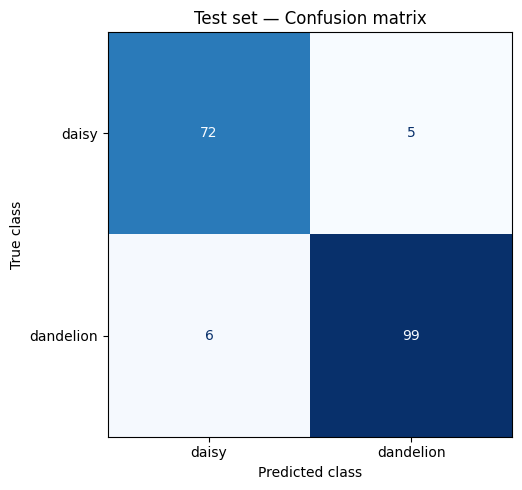

In [ ]:
test_confusion_matrix = confusion_matrix(
  test_targets,
  test_predictions,
  labels = class_indices
)

test_confusion_df = pd.DataFrame(
  test_confusion_matrix,
  index = inference_class_names,
  columns = inference_class_names
)

test_confusion_df.to_csv(Path(METRICS_DIR) / "test_confusion_matrix.csv", index_label = "true_class")

fig, ax = plt.subplots(figsize = (6, 5))

display_matrix = ConfusionMatrixDisplay(
  confusion_matrix = test_confusion_matrix,
  display_labels = inference_class_names
)

display_matrix.plot(
  ax = ax,
  cmap = "Blues",
  values_format = "d",
  colorbar = False
)

ax.set_title("Test set — Confusion matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")

fig.tight_layout()

fig.savefig(
  Path(OUTPUTS_DIR) / "test_confusion_matrix.png",
  dpi = 150,
  bbox_inches = "tight"
)

plt.show()

Salviamo giusto un riepilogo che identifichi anche il modello valutato.

In [ ]:
test_summary = {
  "selected_experiment": final_checkpoint.get("selected_experiment", "not specified"),
  "model_name": final_checkpoint["model_name"],
  "best_epoch": int(final_checkpoint["epoch"]),
  "validation_f1_macro": float(final_checkpoint["valid_metrics"]["f1_macro"]),
  "test_metrics": test_metrics,
  "class_to_idx": inference_class_to_idx
}

with open(Path(METRICS_DIR) / "test_metrics.json", "w", encoding = "utf-8") as file:

  json.dump(
    test_summary,
    file,
    indent = 2,
    ensure_ascii = False
  )

Associamo ogni predizione all’immagine corrispondente:

In [ ]:
test_dataset = data_loaders["test"].dataset

expected_targets = np.asarray([
  target
  for _, target in test_dataset.samples
])

if not np.array_equal(test_targets, expected_targets):
  raise RuntimeError("Test prediction order differs from dataset sample order.")

test_predictions_df = pd.DataFrame({
  "path": [
    path
    for path, _ in test_dataset.samples
  ],
  "true_class": [
    inference_class_names[index]
    for index in test_targets
  ],
  "predicted_class": [
    inference_class_names[index]
    for index in test_predictions
  ],
  "predicted_probability": test_probabilities.max(axis = 1),
  "correct": test_targets == test_predictions
})

for index, class_name in enumerate(inference_class_names):
  test_predictions_df[f"probability_{class_name}"] = (test_probabilities[:, index])

test_predictions_df.to_csv(Path(METRICS_DIR) / "test_predictions.csv", index = False)

display(test_predictions_df.head())

print(
  "Test classification errors:",
  int((~test_predictions_df["correct"]).sum())
)

,path,true_class,predicted_class,predicted_probability,correct,probability_daisy,probability_dandelion
0,content/data/Dataset/progetto-finale-flowes/te...,daisy,daisy,1.000000,True,1.000000,1.090250e-07
1,content/data/Dataset/progetto-finale-flowes/te...,daisy,daisy,1.000000,True,1.000000,2.595693e-15
2,content/data/Dataset/progetto-finale-flowes/te...,daisy,daisy,0.999909,True,0.999909,9.053661e-05
3,content/data/Dataset/progetto-finale-flowes/te...,daisy,daisy,1.000000,True,1.000000,4.301683e-09
4,content/data/Dataset/progetto-finale-flowes/te...,daisy,daisy,1.000000,True,1.000000,1.302801e-12


Test classification errors: 11


Creiamo anche una funzione per fare inferenza di un'immagine e testiamola su un'immagine del dataset di test senza caricare nuove immagini:

In [ ]:
def predict_image(image_path, model, transform, class_names, device):
  """
  Classify one image using the selected model.
  """

  image_path = Path(image_path)

  if not image_path.is_file():
    raise FileNotFoundError(f"Image not found: {image_path}")

  image = load_rgb_image(image_path)

  image_tensor = (
    transform(image)
    .unsqueeze(0)
    .to(device)
  )

  model.eval()

  with torch.inference_mode():

    logits = model(image_tensor)
    probabilities = logits.softmax(dim = 1)[0]

  probabilities = probabilities.cpu().tolist()

  predicted_index = int(np.argmax(probabilities))

  return {
    "image_path": str(image_path),
    "predicted_class": class_names[predicted_index],
    "predicted_probability": float(probabilities[predicted_index]),
    "probabilities": {
        class_name: float(probability)
        for class_name, probability in zip(
          class_names,
          probabilities
        )
    }
    }

Utilizziamo un'immagine del dataset di test per fare inferenza:

{
  "image_path": "content/data/Dataset/progetto-finale-flowes/test/daisy/10466290366_cc72e33532_jpg.rf.6ddc91cd5d4a6a683e567ccb37e5a089.jpg",
  "predicted_class": "daisy",
  "predicted_probability": 0.9999998807907104,
  "probabilities": {
    "daisy": 0.9999998807907104,
    "dandelion": 1.090251871005421e-07
  }
}


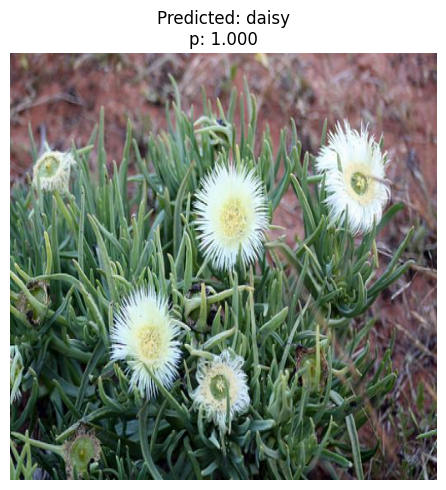

In [ ]:
example_image_path = datasets_images["test"].samples[0][0]

prediction = predict_image(
  image_path = example_image_path,
  model = model,
  transform = eval_transform,
  class_names = inference_class_names,
  device = device
)

print(json.dumps(
  prediction,
  indent = 2,
  ensure_ascii = False
))

fig, ax = plt.subplots(figsize = (5, 5))

ax.imshow(load_rgb_image(example_image_path))

ax.set_title(
  f"Predicted: {prediction['predicted_class']}\n"
  f"p: {prediction['predicted_probability']:.3f}"
)

ax.axis("off")

plt.tight_layout()
plt.show()

In fin dei conti:
- L'esperimento migliore risulta essere la baseline pulita che sul test set di 182 immagini ha ottenuto un’accuracy del `93,96%`, un F1 macro di `0,9382` e una loss di `0,3421`.
- Le prestazioni risultano abbastanza equilibrate tra le due classi, con un F1-score di `0,9290` per i daisy e di `0,9474` per i dandelion.
- La vicinanza tra F1 macro di validazione e di test suggerisce in generale una buona capacità di generalizzazione sui dati.